# Problem

## B(n, p)

p - відома

In [45]:
N = 1000

n = 10
p = 0.2

In [46]:
import numpy as np

In [47]:
x = (np.random.rand(N, n) < p).sum(axis=1)

In [48]:
x.max()

np.int64(6)

In [49]:
from scipy.special import digamma

In [50]:
from scipy.optimize import fsolve

In [51]:
def f(n):
    return N * digamma(n + 1) - digamma(n - x + 1).sum() + N * np.log(1 - p)

In [52]:
n_est = fsolve(f, x.max())
n_est

array([10.03628153])

In [55]:
f(n_est)

array([3.69482223e-13])

In [53]:
from scipy.special import binom

def lnL(x, n, p):
    return np.log(binom(n, x)).sum() + x.sum() * np.log(p) + (N * n - x.sum()) * np.log(1 - p)

In [54]:
lnL(x, 7, p), lnL(x, 8, p)

(np.float64(-1759.7295074830893), np.float64(-1668.5406629601716))

In [39]:
 lnL(x, 9, p)

np.float64(-1680.7124135605625)

In [40]:
 lnL(x, 10, p)

np.float64(-1659.8168814038565)

In [41]:
 lnL(x, 11, p)

np.float64(-1665.4868864629875)

In [43]:
t = np.arange(x.max(), x.max() * 100)
max_ind = np.array([lnL(x, n_, p) for n_ in t]).argmax()

In [44]:
t[max_ind]

np.int64(10)

# Problem

## B(n, p)

p - невідом

In [ ]:
N = 1000

n = 10
p = 0.2

In [56]:
x = (np.random.rand(N, n) < p).sum(axis=1)

In [58]:

def f2(param):
    n, p = param
    return [
        N * digamma(n + 1) - digamma(n - x + 1).sum() + N * np.log(1 - p),
        p - x.mean() / n
    ]

In [63]:
n_est, p_est = fsolve(f2, [x.max(), 1 / x.mean()])

C:\Users\v.miroshnychenko\AppData\Local\Temp\ipykernel_5048\4078535207.py:1: RuntimeWarning: The number of calls to function has reached maxfev = 600.
  n_est, p_est = fsolve(f2, [x.max(), 1 / x.mean()])


In [64]:
n_est, p_est

(np.float64(10.564214480414439), np.float64(0.19486874427177114))

In [81]:
n_est, p_est = fsolve(f2, [x.max(), 0.5])

C:\Users\v.miroshnychenko\AppData\Local\Temp\ipykernel_5048\1718445765.py:1: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  n_est, p_est = fsolve(f2, [x.max(), -5])


In [82]:
n_est, p_est

(np.float64(40.87498568221594), np.float64(0.05011917670993319))

In [80]:
f2([n_est, p_est])

[np.float64(-5.108208137016845e-05), np.float64(0.0009663549867586219)]

In [83]:
from scipy.optimize import minimize

In [84]:
# minimize()

# Problem 2

In [118]:
n = 100

lam = 0.25#1.345

x = np.random.exponential(1 / (lam + 1 / lam), size=n)

In [119]:
(lam + 1 / lam), 1 / x.mean()

(4.25, np.float64(3.812640151052257))

In [120]:
from scipy.stats import expon

# def lnL(x, l):
#     ll = l + 1 / l
#     return np.log(expon(0, 1 / ll).pdf(x)).sum()


def lnL(x, l):
    ll = l + 1 / l
    return len(x) * np.log(ll) - x.sum() * ll

In [123]:
t = np.linspace(0.2, 5, 1001)

from matplotlib import pyplot as plt

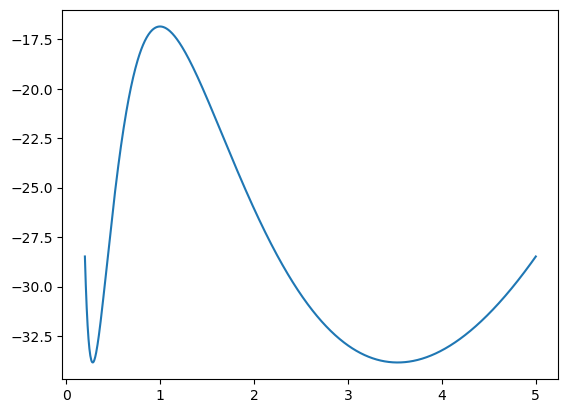

In [134]:
plt.plot(t, [-lnL(x, l) for l in t])

In [132]:
minimize(lambda l: -lnL(x, l), [5])

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -33.832190218959866
        x: [ 3.529e+00]
      nit: 5
      jac: [-9.537e-07]
 hess_inv: [[ 1.722e-01]]
     nfev: 12
     njev: 6

In [137]:
res = minimize(lambda l: -lnL(x, l), [0.25])
res.x

array([0.28334249])

In [140]:
res = minimize(lambda l: -lnL(x, l), [5])
res.x

array([3.52929727])

In [ ]:
res = minimize(lambda l: -lnL(x, l), [0.5], bounds=[(1e-10, None)],)

In [141]:
res = minimize(lambda l: -lnL(x, l), [0.5], bounds=[(1e-10, None)],)

In [143]:
res.x

array([0.28334249])